# Validation: how the arms are tested

**What this answers:** How the years are split, how many rows each test has, which safety checks passed, and how stable results are over years.

**What it reads:** The per-year prediction files, the guard results and the per-year metric table.

**What to expect:** A fold diagram, row counts, the guard table and a stability plot.

Load the reporting helpers.

In [1]:
from wildfire.reporting import validation
from IPython.display import display

**Folds.** Each year is scored by models fitted only on earlier years. There are no random splits.

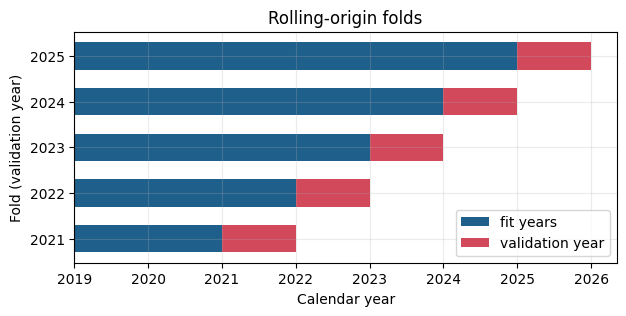

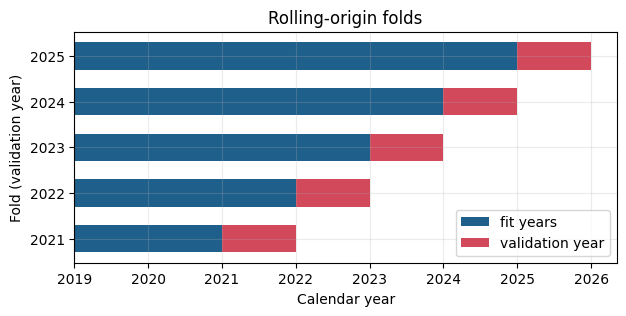

In [2]:
validation.plot_folds()

**Rows per fold.** Number of validation rows and onsets in each year.

In [3]:
display(validation.fold_table())

,validation_year,fit_years,rows,onsets
0,2021,2019-2020,1034752,57080
1,2022,2019-2021,839785,44058
2,2023,2019-2022,939632,50420
3,2024,2019-2023,726279,37679
4,2025,2019-2024,980554,51258


**Safety checks.** All of these must pass before any score is written.

In [4]:
display(validation.guards_table())

,check,result
0,timestamp_before_day,True
1,shifted_feature_fails,True
2,label_shuffle,True
3,label_shuffle_mean_auc,0.5012311643343151
4,coordinate_unit_test,True
5,no_validation_information_in_tuning,True
6,geo_ledger,True
7,provenance,True
8,code_version,3dc2e937bf556622cba4313f6c6ea746ac2fd692
9,code_commit,3dc2e937bf556622cba4313f6c6ea746ac2fd692


**Stability over years.** A result that only holds in one year is not trusted.

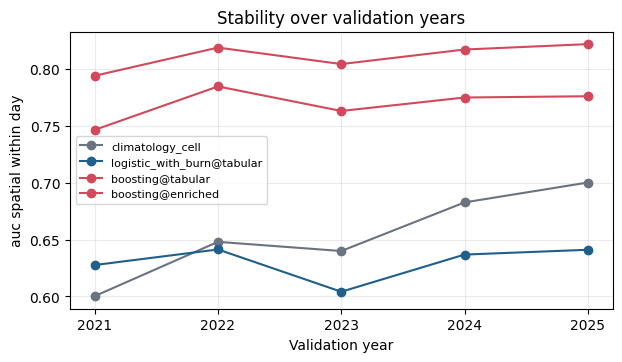

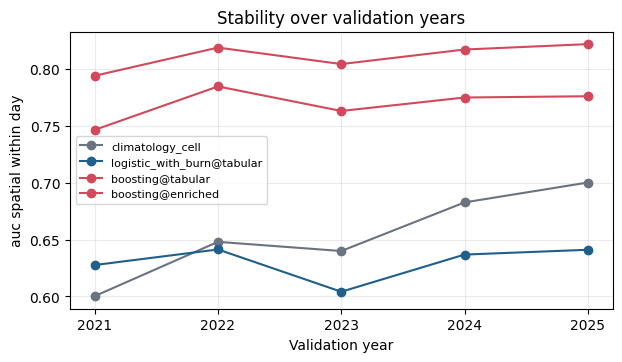

In [5]:
validation.plot_by_year()

## What this shows

Each validation year has its own fit years, and the guard table lists every safety check with its result.

## What it does not show

It does not show skill on truly new data: 2025 was looked at in earlier work, and the sealed 2026 season is unavailable.